In [114]:
import pandas as pd
import matplotlib.pyplot as plt # viz
import seaborn as sns # better viz
import numpy as np # numerical python

%matplotlib inline
pd.set_option('display.max_columns', None)

In [115]:
# Load and create a copy of the data
data = pd.read_csv("amz_uk_price_prediction_dataset.csv")
df = data.copy()

In [116]:
# Confirm all looks good
df.head()

# Basics of the dataset were already explored in the univariate analysis section

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


## 1. Analysing Best-Seller Trends Across Product Categories

**Objective: Understand the relationship between product categories and their best-seller status.**

### 1.1 Crosstab analysis

In [117]:
bestseller_ct = pd.crosstab(df["category"], df["isBestSeller"])
display(bestseller_ct)

isBestSeller,False,True
category,,
3D Printers,247,1
3D Printing & Scanning,4065,2
Abrasive & Finishing Products,245,5
Action Cameras,1696,1
Adapters,251,3
...,...,...
Wind Instruments,243,7
Window Treatments,234,5
Women,17559,213


In [118]:
# add a column to the crosstab with the proportion of bestsellers in a category
bestseller_ct["proportion"] = bestseller_ct[True] / (bestseller_ct[True] + bestseller_ct[False])
display(bestseller_ct)

isBestSeller,False,True,proportion
category,,,
3D Printers,247,1,0.004032
3D Printing & Scanning,4065,2,0.000492
Abrasive & Finishing Products,245,5,0.020000
Action Cameras,1696,1,0.000589
Adapters,251,3,0.011811
...,...,...,...
Wind Instruments,243,7,0.028000
Window Treatments,234,5,0.020921
Women,17559,213,0.011985


In [119]:
bestseller_ct.sort_values(by="proportion", ascending=False, inplace=True)
display(bestseller_ct)
display(bestseller_ct.head(15))

isBestSeller,False,True,proportion
category,,,
Grocery,9008,556,0.058135
Smart Home Security & Lighting,98,6,0.057692
Health & Personal Care,9017,552,0.057686
Mobile Phone Accessories,248,11,0.042471
Power & Hand Tools,8353,306,0.035339
...,...,...,...
"CD, Disc & Tape Players",8798,0,0.000000
General Music-Making Accessories,259,0,0.000000
Snowboard Boots,1449,0,0.000000


isBestSeller,False,True,proportion
category,,,
Grocery,9008,556,0.058135
Smart Home Security & Lighting,98,6,0.057692
Health & Personal Care,9017,552,0.057686
Mobile Phone Accessories,248,11,0.042471
Power & Hand Tools,8353,306,0.035339
"Billiard, Snooker & Pool",241,8,0.032129
Pet Supplies,9152,285,0.030200
Home Brewing & Wine Making,239,7,0.028455
Wind Instruments,243,7,0.028000


In [120]:
no_best_sellers = (bestseller_ct['proportion'] == 0).sum()
int(no_best_sellers)

36

Sorting the crosstab between product categories and bestseller status by the proportion of bestsellers in any given product category shows that no category has more than 6% of its products tagged as bestsellers, with the Grocery category having the highest percentage with 5.81%. The percentage also drops quite rapidly, with only seven categories having 3% or more of its products marked as best sellers. Notably there are also many smaller product categories featured in the top 15 of best sellers by proportion: while five of the categories have thousands of items each, the other ten have less than 250 items each.

Checking for 0 values in the proportion calculation column, we can also see that 36 columns have no bestsellers.

### 1.2 Statistical Tests

In [121]:
bestseller_ct.drop(columns=["proportion"], inplace=True)

In [122]:
from scipy.stats import chi2_contingency

_, chi2_value, _, _ = chi2_contingency(bestseller_ct)

float(chi2_value)

0.0

In [123]:
float(chi2_value) < 0.05

True

The p-value of 0.0 yielded from the Chi-square test suggest an extremely significant association between the category and the best-seller distribution. The perfect 0 is likely yielded by a p-value smaller than the precision available to the computation.

In [124]:
from scipy.stats.contingency import association

association(bestseller_ct, method="cramer")

0.1222829439760564

The Cramer's V computation result of 0.122 suggest a weak association between the product category and best seller status.

### 1.3 Visualisation

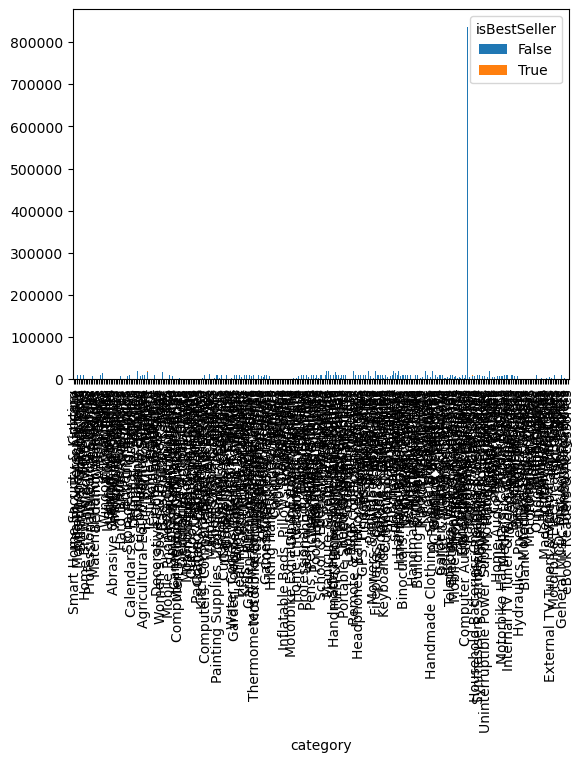

In [125]:
bestseller_ct.plot(kind="bar", stacked=True)
plt.show()

Visualising the complete crosstab in a stacked bar chart does not yield readable or interpretable results as the number of categories is high and the number of products per category is significantly skewed to one category and the proportions of bestsellers per category are quite small.

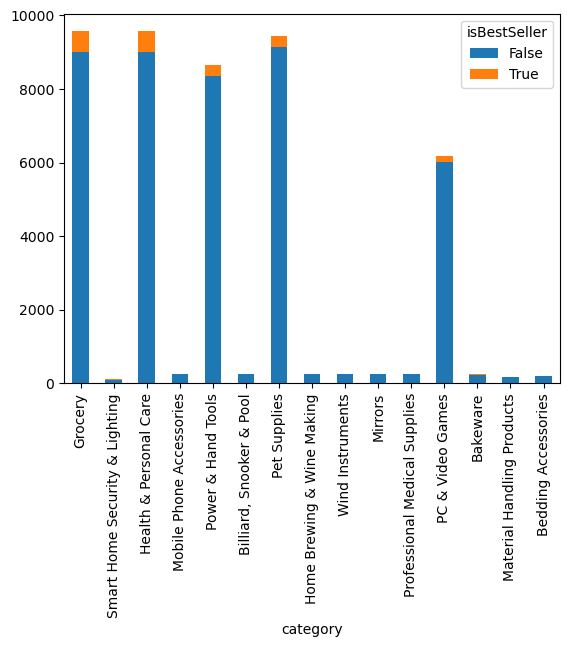

In [126]:
bestseller_ct.head(15).plot(kind="bar", stacked=True)
plt.show()

Visualising just the top 15 categories by proportion of best sellers is more reasonable, but further illustrates the problem from above: even in the better spaced plot, many categories have so few products compared to others that their count of bestsellers is negligible enough to be invisible in the plot. 

## 2. Exploring Product Prices and Ratings Across Categories and Brands

**Objective: Investigate how different product categories influence product prices.**

### 2.0 Remove product price outliers

In [127]:
# get Q1 and Q3
Q1 = df["price"].quantile(0.25)
Q3 = df["price"].quantile(0.75)

# calculate interquantile range
IQR = Q3 - Q1

# define outlier boundaries
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# filter the dataframe based on price outliers
filtered_data = df[(df["price"] >= lower_bound) & (df["price"] <= upper_bound)]

display(filtered_data)

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers
...,...,...,...,...,...,...,...,...,...
2443646,2828589,B0CHSD7P2Q,"Motorbike Armour, Motorbike Clothing, Cycling ...",0.0,0,22.34,False,0,Motorbike Clothing
2443647,2828590,B0B7B8FNBQ,PROFIRST Waterproof Motorcycle 2 Piece Ladies ...,0.0,0,97.99,False,0,Motorbike Clothing
2443648,2828591,B0BD5FL5FB,Men’s Motorcycle Motorbike Biker Trousers Kevl...,0.0,0,52.99,False,0,Motorbike Clothing
2443649,2828592,B008OYLL4I,Texpeed Mens Motorcycle Motorbike Biker Trouse...,4.3,404,79.99,False,0,Motorbike Clothing


In [128]:
print(df.shape)
print(filtered_data.shape)

(2443651, 9)
(2115963, 9)


### 2.1 Violin plots

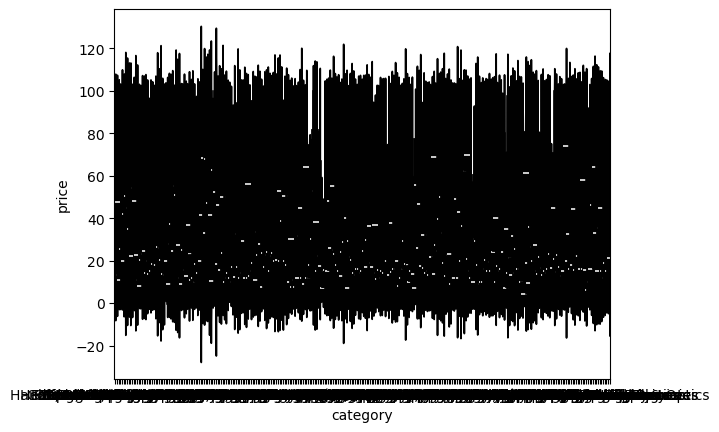

In [129]:
sns.violinplot(data=filtered_data, x="category", y="price", palette="magma", hue="category")
plt.show()

Having all product categories in a single visualisation does not yield readable results.

In [130]:
top_cats = filtered_data["category"].value_counts().nlargest(20).index

partial_data = filtered_data[filtered_data["category"].isin(top_cats)]

In [131]:
partial_data

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
19513,21072,B09477KHQ3,"Personalised Birthday Print Gift ""THE YEAR YOU...",4.5,763,7.99,False,900,Handmade Home & Kitchen Products
19514,21073,B0BSRFQYG8,Wax Melts 4 Bars | Build Your Own Box (Choose ...,3.9,117,6.49,True,800,Handmade Home & Kitchen Products
19515,21074,B09N9GVHV9,"Personalised Birthday Print Gift ""ON THE DAY/Y...",4.6,1155,8.99,True,600,Handmade Home & Kitchen Products
19516,21075,B0BRYGV7PQ,Fresh Wax Melts - Laundry Type Wax Melts - Str...,4.5,56,4.99,True,500,Handmade Home & Kitchen Products
19517,21076,B0B1JHB28R,Manta Makes Work Leaving Gifts | I Used to Wor...,4.7,261,9.95,True,400,Handmade Home & Kitchen Products
...,...,...,...,...,...,...,...,...,...
2429088,2806950,B0045I6SHW,Cannondale Men's Bibshort Dart Team Bike Shorts,0.0,0,99.67,False,0,Sports & Outdoors
2429089,2806951,B0045I6NZY,Cannondale Men's Baggy Fitness Bike Shorts,0.0,0,20.62,False,0,Sports & Outdoors
2429090,2806952,B003BLON3A,Pearl iZUMi Men's Phase Splice Knicker,4.3,3,59.86,False,0,Sports & Outdoors
2437153,2818782,B091HG57TP,Goodstoworld Boys Girls Tracksuit Bottoms 3D S...,4.2,554,14.99,False,0,Sports & Outdoors


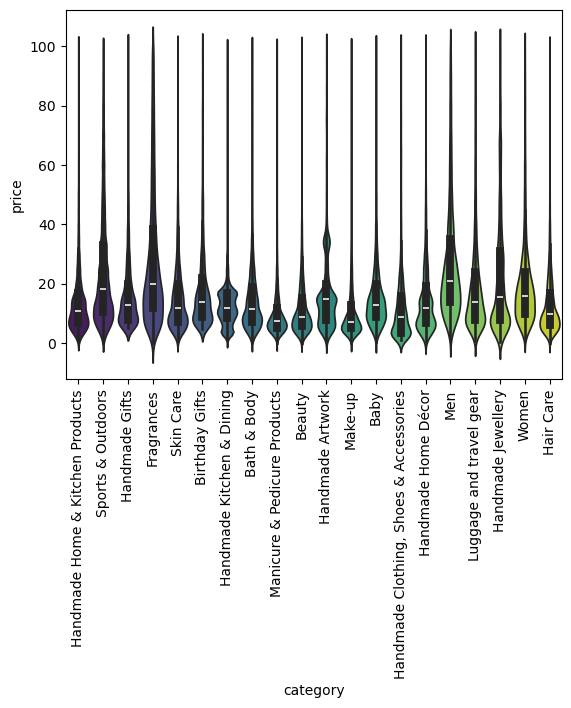

In [132]:
sns.violinplot(data=partial_data, x="category", y="price", palette="viridis", hue="category")
plt.xticks(rotation=90)
plt.show()

Based on the violin plots, the highest median price appears to be in the category "Men", closely followed by "Fragrances".

In [149]:
prices = filtered_data.groupby("category")["price"]
median_prices = prices.median()
median_prices.sort_values(ascending=False, inplace=True)
display(median_prices)


category
Desktop PCs              74.00
Boxing Shoes             69.79
Tablets                  69.00
Graphics Cards           68.54
Motherboards             67.92
                         ...  
Adapters                  7.05
Make-up                   7.00
Signs & Plaques           6.99
Arts & Crafts             5.99
Office Paper Products     4.37
Name: price, Length: 296, dtype: float64

Calculating for median prices, we find that the highest median price is in the category "Desktop PCs" at a median of GBP74.00.

### 2.2 Bar Charts

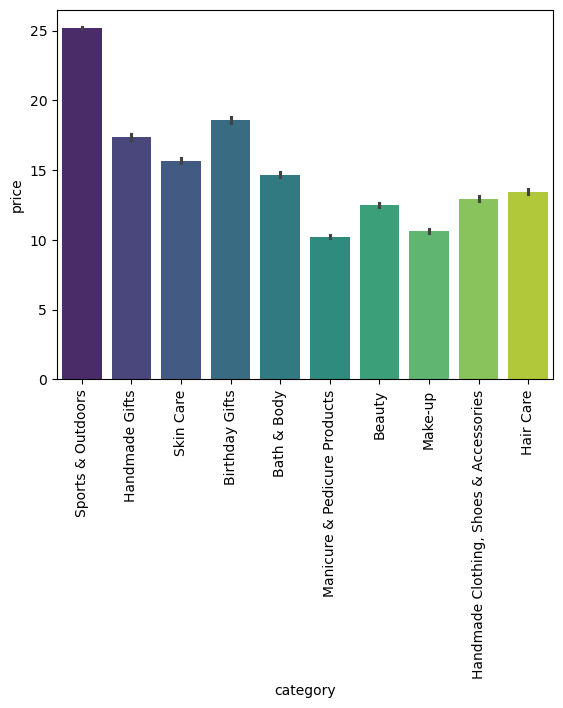

In [135]:
partial_data = filtered_data[filtered_data["category"].isin(top_cats[:10])]
sns.barplot(data=partial_data, x="category", y="price", hue="category", palette="viridis")
plt.xticks(rotation=90)
plt.show()

Within the top ten most populated categories, Sports & Outdoors has the highest average price, leading the following average by about 20%.

In [150]:
mean_prices = prices.mean()
mean_prices.sort_values(ascending=False, inplace=True)
display(mean_prices)

category
Motherboards             68.772432
Boxing Shoes             67.417803
Desktop PCs              66.915562
Tablets                  66.552971
Graphics Cards           65.103509
                           ...    
Bedding Accessories       8.835220
Adapters                  8.750197
Signs & Plaques           8.210513
Arts & Crafts             8.006540
Office Paper Products     6.876369
Name: price, Length: 296, dtype: float64

Calculating average prices by category, we see that the highest mean price is in the "Motherboards" category at GBP68.77.

### 2.3 Box plots

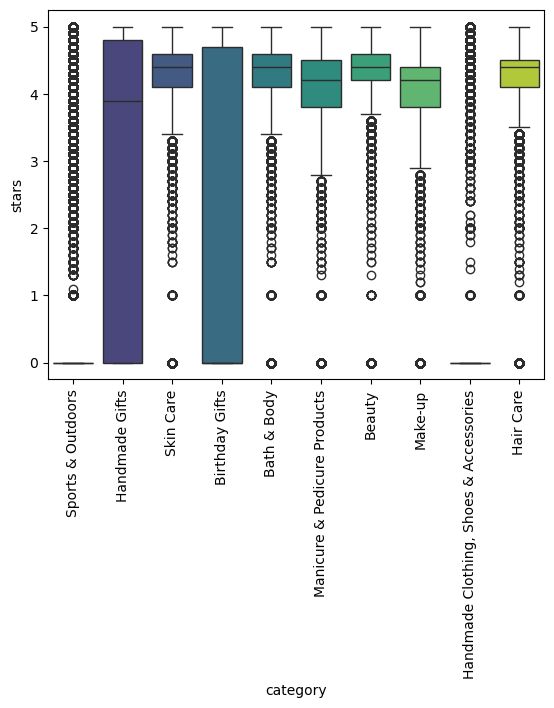

In [134]:
sns.boxplot(x=partial_data["category"], y=partial_data["stars"], palette="viridis", hue=partial_data["category"] )
plt.xticks(rotation=90)
plt.show()

The boxplots suggest that the categories with the median scores are "Skin Care", "Bath & Body" and "Beauty", with differences small enough that they are not fully apparent in the visualisation.

In [153]:
stars = filtered_data.groupby("category")["stars"]
median_stars = stars.median()
median_stars.sort_values(ascending=False, inplace=True)
display(median_stars)

category
Computer Memory                 4.7
Building & Construction Toys    4.6
Office Paper Products           4.6
Luxury Food & Drink             4.6
Kids' Play Figures              4.6
                               ... 
Hockey Shoes                    0.0
Hi-Fi Receivers & Separates     0.0
Handmade Kitchen & Dining       0.0
Handmade Jewellery              0.0
eBook Readers & Accessories     0.0
Name: stars, Length: 296, dtype: float64

Calculating the median star ratings by category shows that the highest median rating is in the "Computer Memory" category with 4.7 stars.

## 3 . Investigating the Interplay Between Product Prices and Ratings

**Objective: Analyze how product ratings (stars) correlate with product prices.**

### 3.1 Correlation Coefficients

In [154]:
pearson_coef = round(float(filtered_data["price"].corr(filtered_data["stars"], method="pearson")), 2)
spearman_coef = round(float(filtered_data["price"].corr(filtered_data["stars"], method="spearman")), 2)

print(f"Between the price and the star rating, the Pearson correlation coefficient is {pearson_coef} and the Spearman correlation coefficient is {spearman_coef}.")

Between the price and the star rating, the Pearson correlation coefficient is -0.08 and the Spearman correlation coefficient is -0.07.


The Pearson correlation coefficient between the price and product rating is -0.08, suggest extremely weak or no linear correlation between the two.

The Spearman correlation coefficient at -0.07 also suggests extremely weak or no monotonous correlation between the two values.

### 3.2 Visualisations

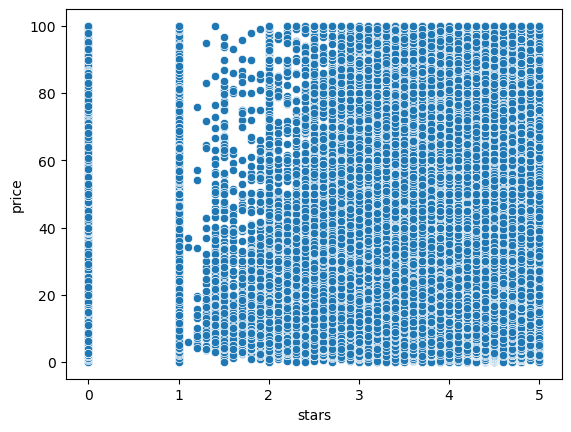

In [158]:
sns.scatterplot(data=filtered_data, x="stars", y="price")
plt.show()

A scatter plot attempting to visualise the relationship between the price and star rating of a product does not yield much information, as most of the graph is very populated. There is some scarcity in data to be observed in products with a star rating between one and two, as the price increases, suggesting that there are less high priced products being rated very lowly.

In [ ]:
# extract numerical data columns
num = filtered_data.select_dtypes(include="number")
num

,uid,stars,reviews,price,boughtInLastMonth
0,1,4.7,15308,21.99,0
1,2,4.7,98099,23.99,0
2,3,4.7,15308,21.99,0
3,4,4.7,7205,31.99,0
4,5,4.6,1881,17.99,0
...,...,...,...,...,...
2443646,2828589,0.0,0,22.34,0
2443647,2828590,0.0,0,97.99,0
2443648,2828591,0.0,0,52.99,0
2443649,2828592,4.3,404,79.99,0


In [160]:
num.corr()

,uid,stars,reviews,price,boughtInLastMonth
uid,1.000000,0.030288,0.020236,0.001717,0.017116
stars,0.030288,1.000000,0.083920,-0.077673,0.113994
reviews,0.020236,0.083920,1.000000,-0.008498,0.105624
price,0.001717,-0.077673,-0.008498,1.000000,-0.059051
boughtInLastMonth,0.017116,0.113994,0.105624,-0.059051,1.000000


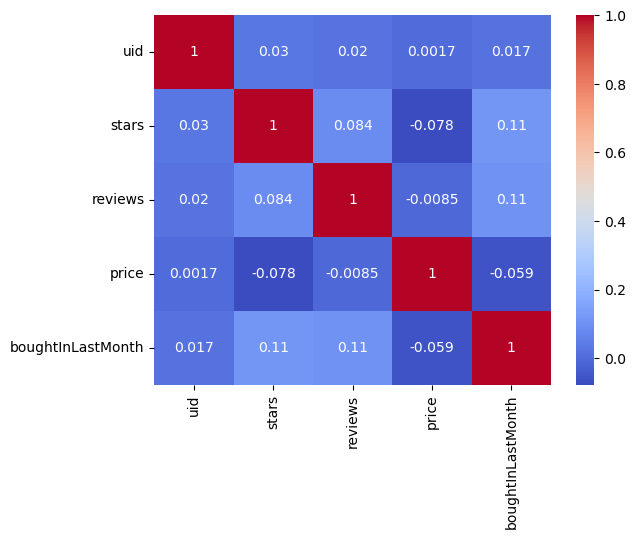

In [164]:
sns.heatmap(num.corr(), cmap="coolwarm", annot=True)
plt.show()

The correlation heatmap suggests that there is very little correlation between any numerical values in the dataset.

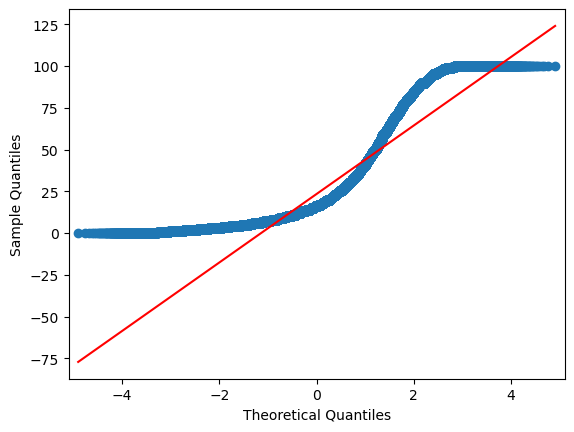

In [165]:
import statsmodels.api as sm

sm.qqplot(filtered_data["price"], line="s")
plt.show()

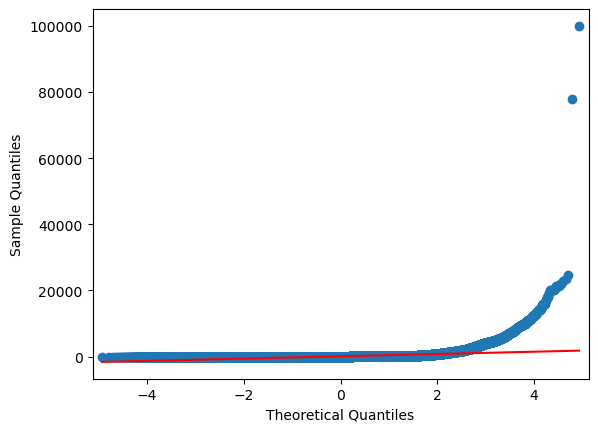

In [166]:
sm.qqplot(df["price"], line="s")
plt.show()

The QQ plot visualising the data with the outliers does not follow a normal distribution as whole. A section of the data in the mid range of prices briefly follows the standardised line. The tails are flattened and do not follow the line, deviating significantly from normal distribution. 
In this visualisation, some of the plateauing is caused by the boundaries set on the data when the outliers were filtered out.

In the second QQ plot, which visualises the unfiltered price data, a significant portion of the data follow the standardised line, until the high end of prices where the sample quantiles are much higher than the expected theoretical quantiles. The upper tail suggests that the data is skewed to the right.